## Pegasus Evaluation: Fine-Tuning

Section C.1. Setup, methods and metrics: `2_B1_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.

In [1]:
# Data source of C.1: "real", the measured runs of a chain of B.1 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
print(f"{data_source} data, {len(seeds)} seeds")

real data, 3 seeds


### C.1 Fine-Tuning Bounds with End-to-End Samples

The question: after $n$ end-to-end samples of a composition, how much tighter does the bound get, and does it still
hold on new runs of that composition? A *run* is one measurement of a few hundred requests at one configuration and
arrival rate; an *end-to-end sample* is a run of the composition whose end-to-end latencies and latencies per service
are known.

- **Chain and split:** V1 of B.1 (detector → transformer → compressor, `C1_CHAIN`). Its held-out runs of B.1
  (configurations drawn at random, up to `MAX_WORKERS` workers per service, every run at half the capacity of its
  busiest service) are put in a random order per seed: the first `C1_POOL` are the samples, of which every method gets
  the first $n$ (one value of `c1_sizes` per setting; $n = 0$ is the bound without fine-tuning); the others are the
  test runs, the same for every $n$. Samples and test runs are drawn the same way, so they are exchangeable, which
  is what the guarantee of split-conformal calibration needs.
- **Ground truth:** per test run, the measured p95 and the lower edge of its confidence interval
  (`measured_quantiles`, batch means, as in B.1). A method *covers* a test run if its prediction is not below that
  lower edge; it *holds* if it covers at least a share $\gamma$ = `confidence` of the test runs under every seed.
- **Pegasus (pretrained):** the bound of B.1 with its load-aware models (`same_information_methods`): per seed the same
  training runs (benchmarks of the services) and GPs as B.1. The bound is multiplied by the split-conformal factor of
  `pegasus/finetuning.py`, the $\lceil (n+1)\gamma \rceil$-th smallest ratio measured p95 ÷ bound over the samples.
  That rank exists only for $n \ge \gamma / (1 - \gamma)$ (`c1_calibrated`); with fewer samples Pegasus keeps the
  bound of B.1. Then a new run of the chain lies below the fine-tuned bound with probability at least $\gamma$.
- **Pegasus (blank):** the same bound without the pretraining on the benchmarks, on the same $n$ samples as the
  baselines. Its GPs are trained on the first $\min(n, m)$ samples, $m$ = `C1_GP_RUNS`; a sample gives every service
  one training run: its mean execution time (mean processing time plus the handling overhead of the run) and its
  spread ((p95 − median) ÷ 1.645 of the processing time), as the training runs of B.1 (`training_pool`), with the
  inputs of the load-aware models. The samples after the first $m$ calibrate the bound like the samples of Pegasus
  (pretrained), because split-conformal calibration needs samples that the models did not train on: up to $n = m$
  every sample trains and the bound is not calibrated; beyond, the GPs stay as they are and the $n - m$ later samples
  calibrate it (from `c1_calibrated` of them on). It has no point at $n = 0$.
- **Baselines trained on the samples** (`pegasus/finetuning.py`): *Quantile Sum* (one GP per service of the p95 of its
  latency inside the chain, waiting plus processing, the predictions summed) and *Fluxion-style* (one GP per position,
  fed by the predicted quantiles of the position before it). Their inputs are those of the load-aware models: per
  service its knobs, workers and log10 of the arrival rate. Both add the handover between the services, $(K-1)\,h$
  with $K$ the number of services and $h$ the handover per hop of the platform (`platform_handover`), which the bound
  contains and no service latency does. Neither is a bound.

Figure: `figures/tsc/experimental-results/c1_finetuning_real`, half the width of an evaluation figure: the tightness
(prediction ÷ measured p95 per test run, the median over the test runs) over the number of samples $n$; the line is
the median over the seeds and the band the range over the seeds; a filled marker means that the method holds under
every seed, a hollow one that it does not.

In [2]:
if data_source != "real":
    print("C.1 skipped: real data only (the measured runs of a chain of B.1)")
else:
    # C.1 on V1 of B.1: samples and test runs from its held-out runs, the GPs of B.1. This cell imports what it needs itself.
    from dataclasses import replace
    from pegasus import real_data
    from pegasus.data import load_aware
    from pegasus.evaluation import fit_services, hop_time, pegasus_bound
    from pegasus.finetuning import COLORS as C1_COLORS, FLUXION, QUANTILE_SUM, finetuned_bound, fluxion_style, quantile_sum

    C1_CHAIN = f"b1-vision-1-single+b1u-max{MAX_WORKERS}"   # V1 in B.1
    # the two versions of Pegasus in C.1: pretrained on the benchmarks (PROPOSED of B.1, renamed here, in its color) and blank (trained on
    # the end-to-end samples alone)
    PRETRAINED, BLANK = "Pegasus (pretrained)", "Pegasus (blank)"
    METHOD_COLORS[PRETRAINED] = METHOD_COLORS[PROPOSED]
    METHOD_COLORS.update(C1_COLORS)   # colors of the two baselines
    METHOD_COLORS[BLANK] = "tab:olive"
    # the smallest number of samples at which the conformal rank ceil((n + 1) * confidence) is at most n; below it Pegasus
    # keeps the bound of B.1 (calibration_factor)
    c1_calibrated = int(np.ceil(confidence / (1 - confidence) - 1e-9))
    # number of samples; 0 is the bound of B.1 without fine-tuning
    c1_sizes = [0, 10, 20, 40, 60, 80, 100]
    C1_POOL = c1_sizes[-1]   # held-out runs that are samples; the others are the test runs
    C1_GP_RUNS = 50          # samples that train the GPs of Pegasus (blank); the samples after them calibrate its bound
    # the training target of every service in every held-out run of B.1, as training_pool defines it for a training run: the mean
    # execution time (s; mean processing time plus the handling overhead of the run) and the spread (s; (p95 - median) / NORMAL_P95 of the
    # processing time); nan where the run has no measurable handling overhead
    c1_runs = real_data.combined_runs(C1_CHAIN)   # (experiment, run_id) of every held-out run, in the order of real_chain_data
    c1_run_targets = {}
    for node in real_data.chain_path(C1_CHAIN)[0]:
        node_rows = {experiment: real_data.run_table(experiment)[real_data.run_table(experiment)["node"] == node].set_index("run_id")
                     for experiment in dict.fromkeys(experiment for experiment, _ in c1_runs)}
        statistics = pd.concat([node_rows[experiment].loc[[run_id]] for experiment, run_id in c1_runs])
        overhead = np.array([real_data.handling_overhead(experiment, run_id, node) for experiment, run_id in c1_runs])
        c1_run_targets[node] = (statistics["processing_mean_ms"].to_numpy() / 1e3 + overhead,
                                np.maximum((statistics["processing_p95_ms"] - statistics["processing_p50_ms"]).to_numpy() / real_data.NORMAL_P95 / 1e3, 1e-6))

    def compute():
        results, truth = {}, {}   # (size, seed) -> name -> (group, latency per test run in s) / (measured p95, its lower edge) per test run
        with warnings.catch_warnings():
            # the GPs of Pegasus (blank) and of the baselines are fitted on few samples, and scikit-learn warns where their hyperparameters end
            # at their bounds
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in seeds:
                # the data of B.1 for V1 under this seed: its training runs, its held-out runs and their ground truth
                data = load_chain_data("real", experiment=C1_CHAIN, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s],
                                       n_train=N_TRAIN, training_campaign=WORKER_TRAINING)
                assert len(data.measured) == len(c1_runs) > C1_POOL, "the held-out runs differ from combined_runs, or leave no test runs"
                # Pegasus with the load-aware models of B.1 (same_information_methods): the GPs are fitted on the training runs of this seed
                # (read from the model cache, as B.1 fitted them) and give the bound at every held-out run
                view = load_aware(data)
                bound = pegasus_bound(data, fit_services(view, view.x_train, data.y_train, model_seed=seed + s, confidence=confidence,
                                                         with_dnn=False), alpha)
                # the held-out runs in a random order: the samples, then the test runs
                order = np.random.default_rng([seed, s, 100]).permutation(len(data.measured))
                pool, test = order[:C1_POOL], np.sort(order[C1_POOL:])
                for size in c1_sizes:
                    samples = pool[:size]
                    results[(size, s)] = {PRETRAINED: ("proposed", finetuned_bound(bound, data.measured, samples, test, miscoverage=1 - confidence))}
                    if size > 0:
                        for name, method in ((QUANTILE_SUM, quantile_sum), (FLUXION, fluxion_style)):
                            results[(size, s)][name] = ("baseline", method(data, samples, test, alpha) + hop_time(data))
                        # Pegasus (blank): every service trained on the first C1_GP_RUNS samples alone (a sample without a measurable
                        # handling overhead of the service is left out for that service), in the inputs of the load-aware models; its bound at
                        # every held-out run, calibrated with the samples after them (finetuned_bound; none up to C1_GP_RUNS)
                        training, calibration = samples[:C1_GP_RUNS], samples[C1_GP_RUNS:]
                        used = {node: training[np.isfinite(c1_run_targets[node][0][training])] for node in data.path}
                        own = replace(data, x_train_load={node: data.x_test_load[node][used[node]] for node in data.path},
                                      y_train={node: c1_run_targets[node][0][used[node]] for node in data.path},
                                      y_train_spread={node: c1_run_targets[node][1][used[node]] for node in data.path})
                        own_view = load_aware(own)
                        own_bound = pegasus_bound(own, fit_services(own_view, own_view.x_train, own.y_train, model_seed=seed + s,
                                                                    confidence=confidence, with_dnn=False), alpha)
                        results[(size, s)][BLANK] = ("proposed", finetuned_bound(own_bound, data.measured, calibration, test,
                                                                                  miscoverage=1 - confidence))
                    truth[(size, s)] = (data.measured[test], data.measured_low[test])
        return dict(c1_results=results, c1_truth=truth, c1_held_out=len(data.measured))

    # the chain, the sample sizes, the GP runs of Pegasus (blank) and the names of the versions of Pegasus (keys of the results) enter the key
    globals().update(cached("c1_finetuning_chain", data_source, compute,
                            inputs=dict(c1_sizes=c1_sizes, chain=C1_CHAIN, names=(PRETRAINED, BLANK), gp_runs=C1_GP_RUNS)))
    c1_statistics = sweep_statistics(c1_results, c1_truth, c1_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
    c1_test = len(c1_truth[(c1_sizes[0], seeds[0])][0])
    print(f"V1 ({' → '.join(real_data.chain_path(C1_CHAIN)[0])}): {c1_held_out} held-out runs of B.1, per seed {C1_POOL} samples and {c1_test} test runs; "
          f"{len(seeds)} seeds; {PRETRAINED} fine-tuned from n = {c1_calibrated}; {BLANK}: GPs on the first {C1_GP_RUNS} samples, "
          f"calibration with the later ones (from n = {C1_GP_RUNS + c1_calibrated})")

c1_finetuning_chain: results loaded from cache\evaluation\c1_finetuning_chain_real+b1+b1u-max4_c384aaa82f3a3e93.joblib
V1 (detector → transformer → compressor): 149 held-out runs of B.1, per seed 100 samples and 49 test runs; 3 seeds; Pegasus (pretrained) fine-tuned from n = 19; Pegasus (blank): GPs on the first 50 samples, calibration with the later ones (from n = 69)


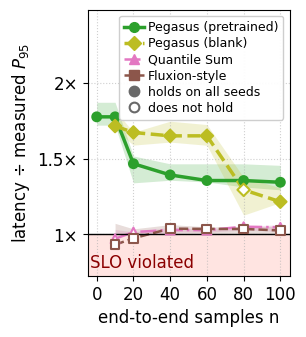

tightness (median over the seeds; ● holds, ○ does not):


,n = 0,n = 10,n = 20,n = 40,n = 60,n = 80,n = 100
Pegasus (pretrained),1.78× ●,1.78× ●,1.47× ●,1.39× ●,1.36× ●,1.36× ●,1.34× ●
Quantile Sum,–,0.97× ○,1.02× ○,1.03× ○,1.03× ○,1.05× ○,1.05× ○
Fluxion-style,–,0.93× ○,0.97× ○,1.04× ○,1.04× ○,1.04× ○,1.03× ○
Pegasus (blank),–,1.72× ●,1.67× ●,1.65× ●,1.65× ●,1.29× ○,1.22× ●


coverage of the test runs (median over the seeds):


,n = 0,n = 10,n = 20,n = 40,n = 60,n = 80,n = 100
Pegasus (pretrained),100%,100%,100%,100%,100%,100%,100%
Quantile Sum,–,67%,86%,88%,90%,92%,92%
Fluxion-style,–,61%,78%,92%,88%,90%,90%
Pegasus (blank),–,100%,100%,100%,100%,100%,100%


In [3]:
if data_source != "real":
    print("C.1 skipped: real data only")
else:
    from pegasus.finetuning import finetuning_figure
    # source: c1_statistics of the cell above; half the width of an evaluation figure; the legend in one column, because two columns are
    # wider than its plot area
    finetuning_figure(c1_sizes, c1_statistics, p_label, output=Path("../../figures/tsc") / "c1_finetuning_real", half=True,
                      legend_options=dict(ncol=1, fontsize=9, handlelength=1.6, handletextpad=0.3, labelspacing=0.25, locations=("upper right",)),
                      styles={PRETRAINED: "o-", BLANK: "D--"}, xlabel="end-to-end samples n",
                      xticks=[0, 20, 40, 60, 80, 100])   # evenly spaced labels; a marker at every sample size
    print("tightness (median over the seeds; ● holds, ○ does not):")
    display(sweep_table(c1_sizes, c1_statistics, list(c1_statistics), lambda size: f"n = {size}"))
    print("coverage of the test runs (median over the seeds):")
    display(pd.DataFrame({f"n = {size}": {name: f"{np.nanmedian(statistics['coverage'][i]):.0%}" if statistics["computed"][i] else "–"
                                          for name, statistics in c1_statistics.items()} for i, size in enumerate(c1_sizes)}))